# 01 · Exploratory analysis and the borderline class

Loads the BCSC risk-factor data (~1.5M records, 12 variables), applies the shared cleaning, looks at class balance, feature distributions and correlations, and then builds the third *borderline* class: a logistic regression is fit on the binary label, and patients **without** cancer whose predicted probability falls in **0.35–0.50** are moved into class 2.

*Outputs below are from the original Google Colab run used in the paper. To rerun, put the three BCSC files in `data/` (see `data/README.md`).*

In [5]:
import pandas as pd
import numpy as np

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # for 3D plot
import seaborn as sns

# EDA

In [7]:
df_1 = pd.read_csv('../data/bcsc_risk_factors_summarized1_092020.csv')
df_2 = pd.read_csv('../data/bcsc_risk_factors_summarized2_092020.csv')
df_3 = pd.read_csv('../data/bcsc_risk_factors_summarized3_092020.csv')

In [8]:
df = pd.concat([df_1, df_2, df_3], ignore_index=True)
print(df.shape)

(1522340, 13)


In [9]:
df.head()

In [10]:
# DROP UNUSED COLUMNS "year" and "count"
df = df.drop(columns=['year', 'count'])

# Making data types categorical
df = df.astype('category')

In [11]:
# Replace 9 with NaN in all columns except "age_group_5_years"
cols_except_age = df.columns[df.columns != 'age_group_5_years']
df[cols_except_age] = df[cols_except_age].replace(9, np.nan)

# Drop rows where breast_cancer_history(target) is NaN
df = df.dropna(subset=['breast_cancer_history'])

In [12]:
# Percentage of NaNs in each column
missing_info = pd.DataFrame({
    'Missing Count': df.isna().sum(),
    'Missing %': (df.isna().sum() / len(df)) * 100
})

print(missing_info)

                       Missing Count  Missing %
age_group_5_years                  0   0.000000
race_eth                       74699   6.269651
first_degree_hx                37109   3.114640
age_menarche                  529232  44.419601
age_first_birth               234599  19.690408
BIRADS_breast_density         144193  12.102434
current_hrt                   124688  10.465337
menopaus                      105394   8.845949
bmi_group                     309681  25.992204
biophx                         22425   1.882179
breast_cancer_history              0   0.000000


In [13]:
# Fill NaN in each remaining column with the mode
for col in df.columns:
    if col != 'breast_cancer_history':
        df[col].fillna(df[col].mode()[0], inplace=True)

In [14]:
print(df.shape)

(1191438, 11)


In [15]:
# One-hot encoding for 'race_eth'
df = pd.get_dummies(df, columns=['race_eth'], drop_first=True)

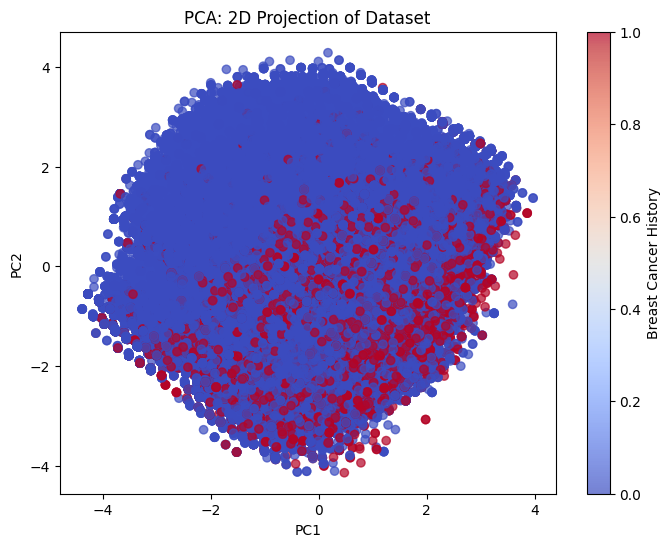

In [16]:
# Separating features and target
X = df.drop(columns=['breast_cancer_history'])
y = df['breast_cancer_history']

# Scaling features for PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Appling PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 2D scatter plot
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=y, cmap='coolwarm', alpha=0.7)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA: 2D Projection of Dataset')
plt.colorbar(label='Breast Cancer History')
plt.show()

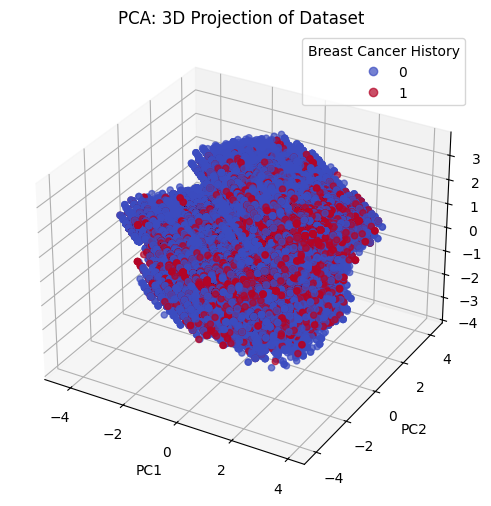

In [17]:
# 3D PCA plot
pca3 = PCA(n_components=3)
X_pca3 = pca3.fit_transform(X_scaled)

fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(X_pca3[:,0], X_pca3[:,1], X_pca3[:,2], c=y, cmap='coolwarm', alpha=0.7)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
plt.title('PCA: 3D Projection of Dataset')
plt.legend(*scatter.legend_elements(), title='Breast Cancer History')
plt.show()

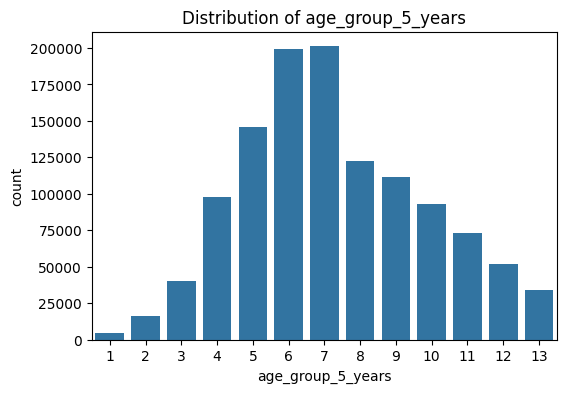

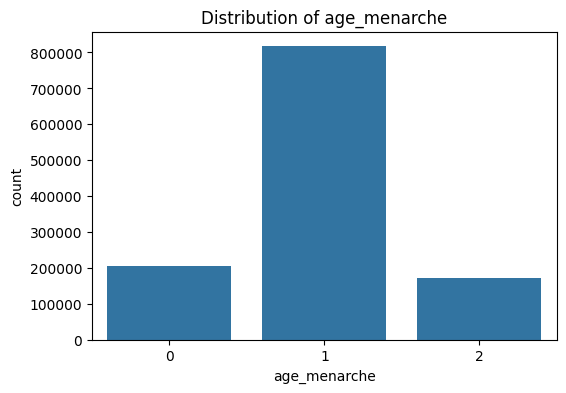

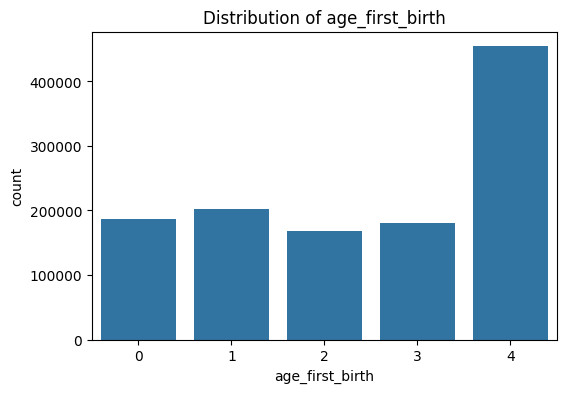

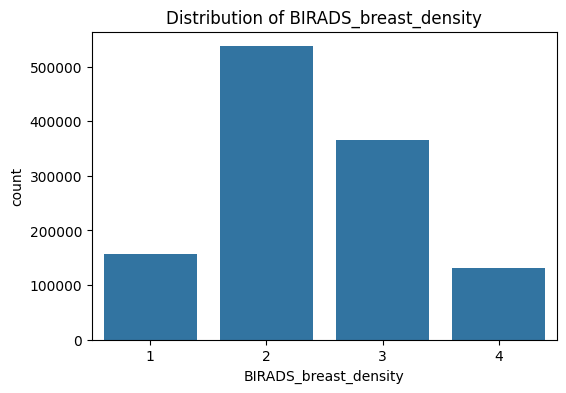

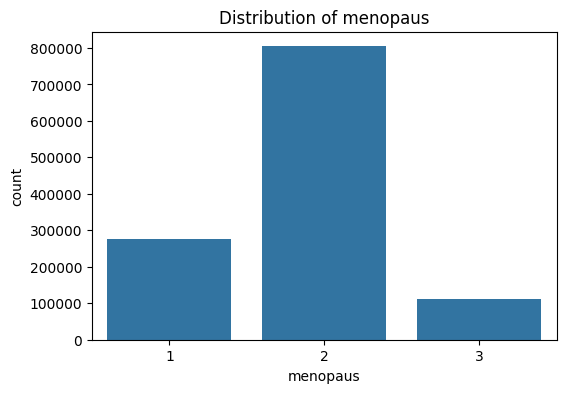

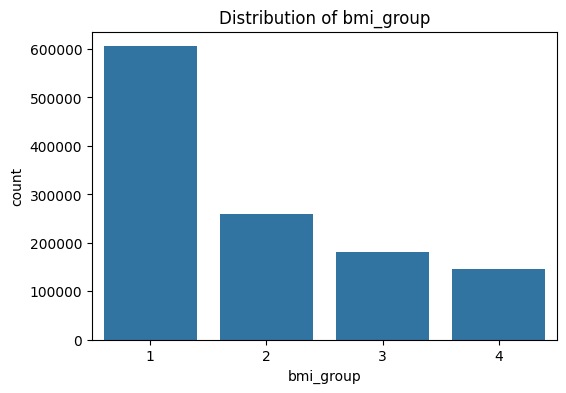

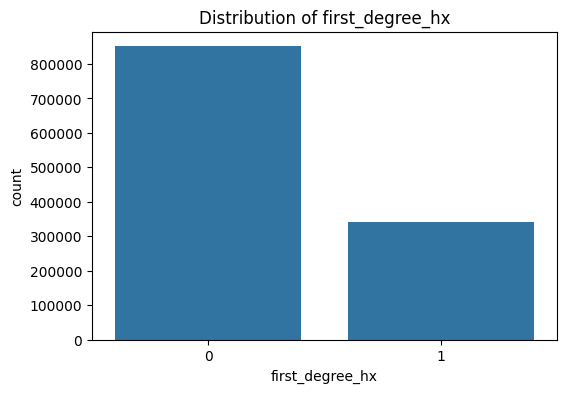

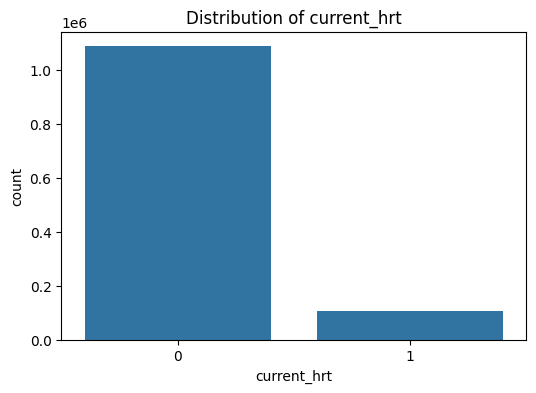

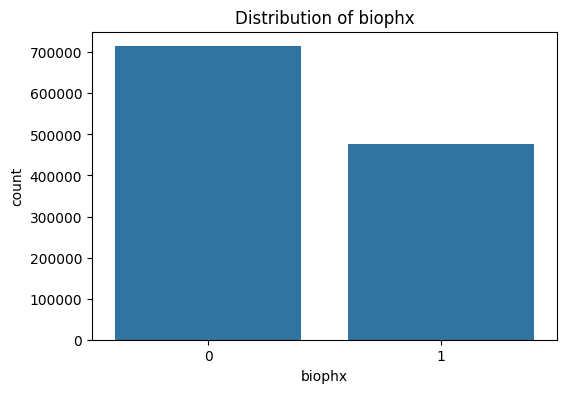

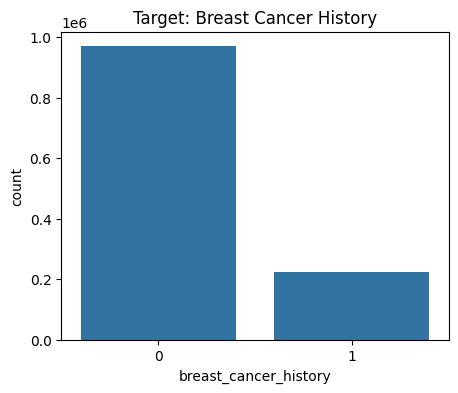

In [18]:
# Histogram / count plot for ordinal/categorical features
ordinal_cols = ['age_group_5_years', 'age_menarche', 'age_first_birth',
                'BIRADS_breast_density', 'menopaus', 'bmi_group',
                'first_degree_hx', 'current_hrt', 'biophx']

for col in ordinal_cols:
    plt.figure(figsize=(6,4))
    sns.countplot(x=col, data=df)
    plt.title(f'Distribution of {col}')
    plt.show()

# Count of target variable
plt.figure(figsize=(5,4))
sns.countplot(x='breast_cancer_history', data=df)
plt.title('Target: Breast Cancer History')
plt.show()

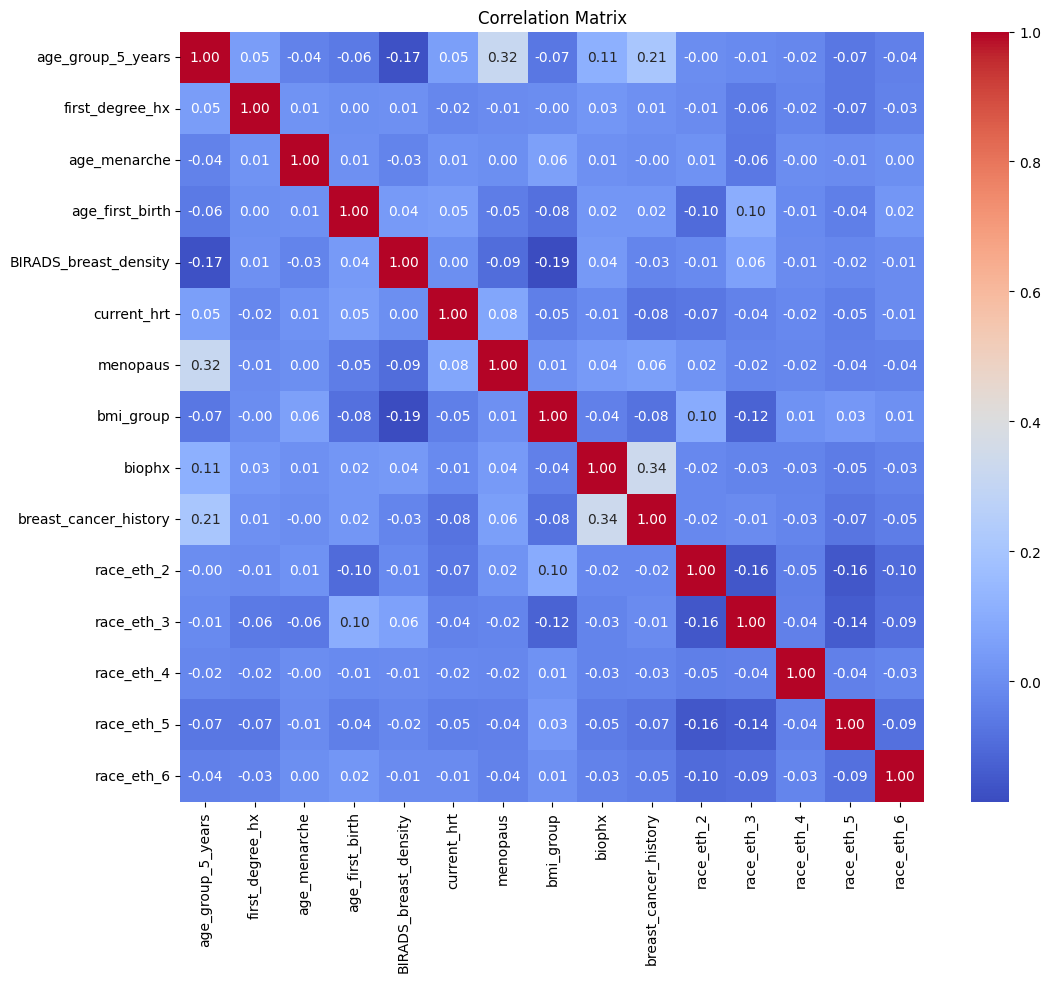

In [19]:
plt.figure(figsize=(12,10))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

# 3rd Class

In [20]:
from sklearn.linear_model import LogisticRegression

# Features & target that were already defined
X = df.drop(columns=['breast_cancer_history'])
y = df['breast_cancer_history']

# Logistic regression
model = LogisticRegression(max_iter=5000)
model.fit(X, y)

# Predicted cancer probability
df['pred_prob'] = model.predict_proba(X)[:, 1]

# New 3-class column (start as copy of y)
df['breast_cancer_history_3class'] = df['breast_cancer_history'].copy()

# Make sure dtype allows category 2
df['breast_cancer_history_3class'] = df['breast_cancer_history_3class'].cat.add_categories([2])

# Thresholds for borderline high-risk class
lower_thresh = 0.35
upper_thresh = 0.50

# Apply new class labeling
borderline_mask = (
    (df['breast_cancer_history'] == 0) &
    (df['pred_prob'] >= lower_thresh) &
    (df['pred_prob'] <= upper_thresh)
)

df.loc[borderline_mask, 'breast_cancer_history_3class'] = 2

# Confirm distribution of classes
print(df['breast_cancer_history_3class'].value_counts())
print(df['breast_cancer_history_3class'].dtype)

breast_cancer_history_3class
0    888887
1    221776
2     80775
Name: count, dtype: int64
category


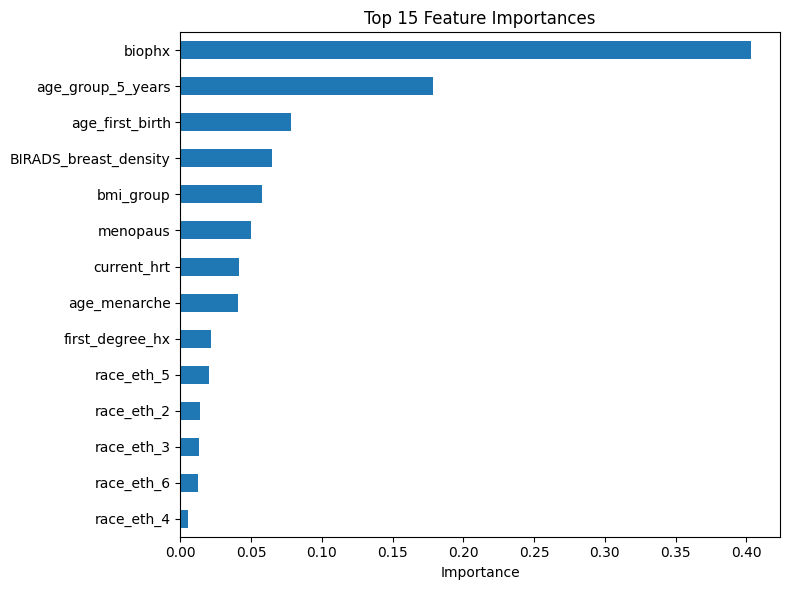

In [24]:
from sklearn.ensemble import RandomForestClassifier

# 1) Choose features (exclude targets and pred_prob)
feature_cols = [
    c for c in df.columns
    if c not in ['breast_cancer_history', 'breast_cancer_history_3class', 'pred_prob']
]

X_rf = df[feature_cols].copy()

# You can choose which target:
#   - binary target        -> 'breast_cancer_history'
#   - 3-class high risk    -> 'breast_cancer_history_3class'
y_rf = df['breast_cancer_history']          # or df['breast_cancer_history_3class']

# 2) Make sure all features are numeric
for col in X_rf.columns:
    if str(X_rf[col].dtype) == 'category':
        X_rf[col] = X_rf[col].cat.codes

# 3) Initialize and train the RandomForestClassifier
rf = RandomForestClassifier(random_state=42) # Added random_state for reproducibility
rf.fit(X_rf, y_rf)

# 4) Plot top 15 most important features
importances = pd.Series(rf.feature_importances_, index=feature_cols)
importances = importances.sort_values(ascending=True)

plt.figure(figsize=(8, 6))
importances.tail(15).plot(kind='barh')
plt.title('Top 15 Feature Importances')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

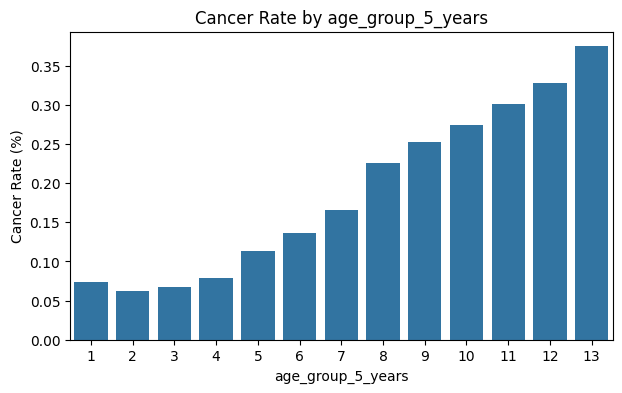

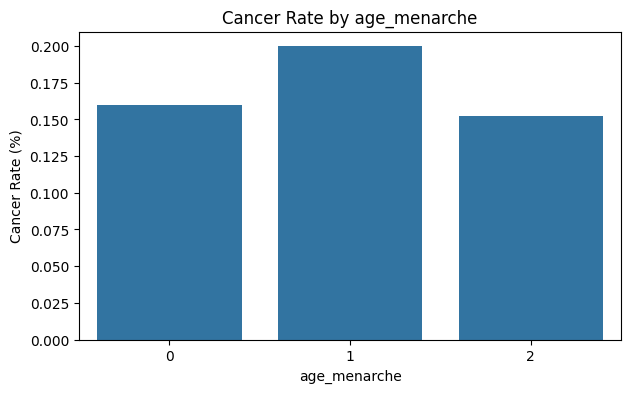

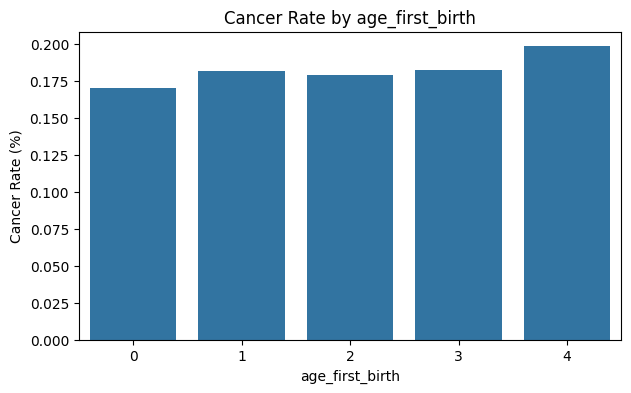

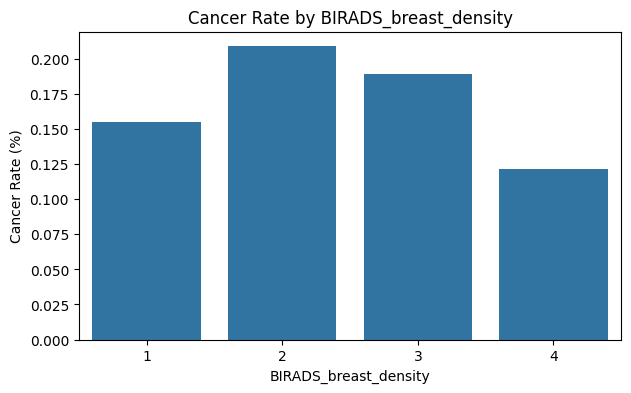

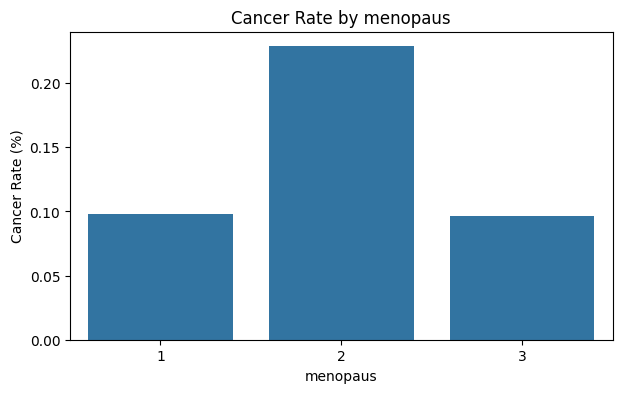

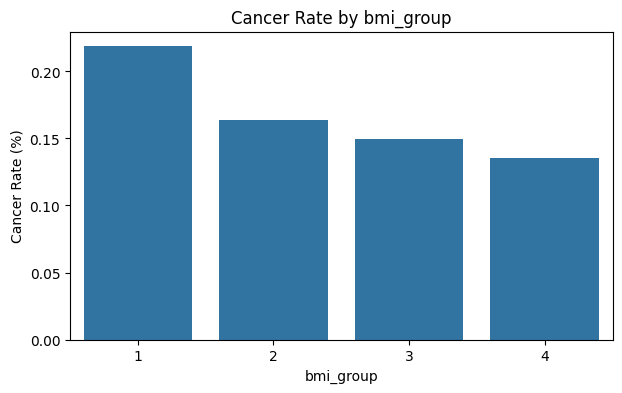

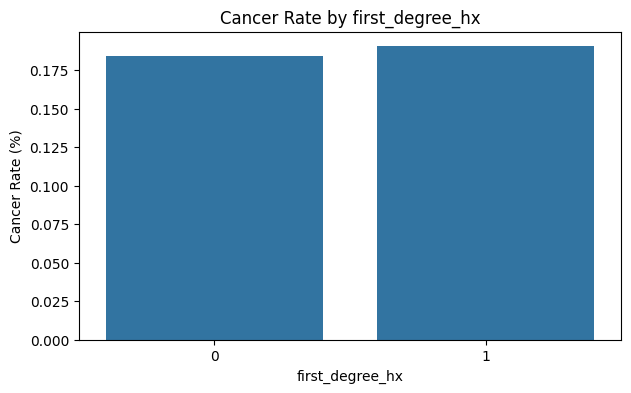

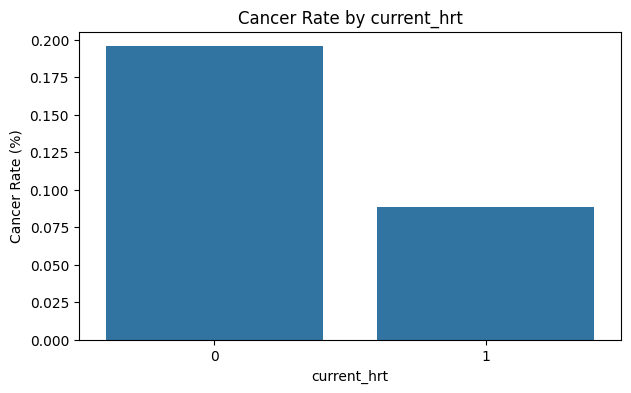

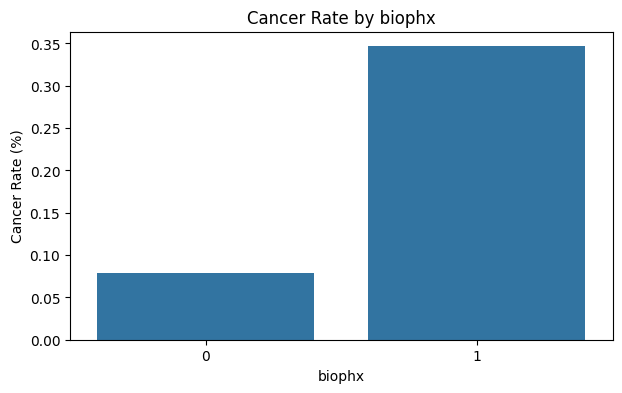

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_cancer_rate(df, col):
    plt.figure(figsize=(7,4))
    # Convert 'breast_cancer_history' to numeric before calculating mean
    cancer_history_numeric = df['breast_cancer_history'].astype(int)
    rate = cancer_history_numeric.groupby(df[col]).mean()
    sns.barplot(x=rate.index, y=rate.values)
    plt.title(f'Cancer Rate by {col}')
    plt.ylabel('Cancer Rate (%)')
    plt.xlabel(col)
    plt.show()

categorical_vars = [
    'age_group_5_years',
    'age_menarche',
    'age_first_birth',
    'BIRADS_breast_density',
    'menopaus',
    'bmi_group',
    'first_degree_hx',
    'current_hrt',
    'biophx'
]

for col in categorical_vars:
    plot_cancer_rate(df, col)